# **CHƯƠNG 5. ỨNG DỤNG SpMV TRONG PHƯƠNG PHÁP LẶP JACOBI**

**Đề tài:** Phép nhân ma trận thưa với vector song song: Phân tích sự bão hòa hiệu năng và ứng dụng trong phương pháp lặp Jacobi  
**Phân công thực hiện:**  
- **Viết báo cáo:** Thành  
- **Cài đặt thuật toán, đo đạc và xuất biểu đồ:** Thanh  

---
Chương này nghiên cứu việc ứng dụng giải thuật nhân ma trận thưa với vector song song (SpMV) vào giải hệ phương trình đại số tuyến tính thưa cỡ lớn $Ax = b$ bằng **Phương pháp lặp Jacobi**. Toàn bộ mã nguồn, thực nghiệm trên 5 hệ phương trình ($N \in \{20000, 60000, 100000, 200000, 600000\}$), kiểm chứng độ chính xác hội tụ, so sánh tốc độ tăng tốc và phân tích tỷ trọng thời gian của nhân SpMV được trình bày chi tiết cùng các biểu đồ trực quan hóa bên dưới.


## **5.1. Giới thiệu bài toán ứng dụng**

Trong khoa học tính toán và kỹ thuật mô phỏng (Computational Science and Engineering), việc giải các hệ phương trình đại số tuyến tính thưa cỡ lớn:
$$A \cdot x = b$$
xuất hiện phổ biến từ bài toán rời rạc hóa phương trình vi phân đạo hàm riêng (PDE), chẳng hạn như **Phương trình Poisson**:
$$\nabla^2 u = f(x, y)$$
Khi rời rạc hóa bằng phương pháp Sai phân hữu hạn (Finite Difference Method) trên lưới không gian 2D/3D (mẫu 5 điểm hoặc 7 điểm stencil), ma trận hệ số $A$ thu được là một ma trận thưa cực lớn, đối xứng và chéo trội.

Với các ma trận thưa từ hàng chục nghìn đến hàng triệu ẩn số, các phương pháp giải trực tiếp (như phép khử Gauss, phân rã LU) đòi hỏi chi phí tính toán $\mathcal{O}(N^3)$ và làm phát sinh các phần tử khác 0 ngoài cấu trúc thưa (fill-in). Do đó, **Phương pháp lặp tuyến tính (Stationary Iterative Methods)**, tiêu biểu là **phương pháp lặp Jacobi**, là giải pháp tối ưu nhờ chi phí mỗi vòng lặp chỉ $\mathcal{O}(nnz)$ và lưu trữ tiết kiệm bằng định dạng CSR.


## **5.2. Xây dựng hệ phương trình**

### Thiết lập hệ đại số tuyến tính thưa:
- **Ma trận hệ số $A$:** Sử dụng 5 ma trận thưa CSR đã xây dựng từ Chương 3 ($N \in \{20000, 60000, 100000, 200000, 600000\}$). Các ma trận này thỏa mãn điều kiện chéo trội nghiêm ngặt:
  $$|A_{ii}| > \sum_{j \neq i} |A_{ij}|, \quad \forall i = 1, \dots, N$$
  Đặc tính này là điều kiện đủ bảo đảm bán kính phổ $\rho(D^{-1} R) < 1$, từ đó phương pháp Jacobi chắc chắn hội tụ với mọi nghiệm khởi tạo ban đầu.
- **Tách ma trận:** $A = D + R$, trong đó:
  - $D = \text{diag}(A_{11}, A_{22}, \dots, A_{nn})$ là ma trận đường chéo chính. Ta tiền tính vector nghịch đảo $D^{-1}$ với các phần tử $D^{-1}_i = \frac{1}{A_{ii}}$.
  - $R = A - D$ là ma trận chứa toàn bộ các phần tử ngoài đường chéo, được lưu trữ tối ưu dưới định dạng thưa CSR.
- **Nghiệm tham chiếu và Vector vế phải:**
  - Khởi tạo nghiệm chuẩn (Ground Truth): $x^* = [1.0, 1.0, \dots, 1.0]^T$.
  - Tính vector vế phải chính xác: $b = A \cdot x^*$.
  - Nghiệm ban đầu của quá trình lặp: $x^{(0)} = [0.0, 0.0, \dots, 0.0]^T$.


In [25]:
import numpy as np
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from numba import njit, prange, set_num_threads
import os

# Cấu hình phong cách biểu đồ chuẩn học thuật
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#29313B'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E2E6EB'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

COLORS = ['#344767', '#7187A5', '#8FA99B', '#D9CBB8', '#E2847A']

def generate_diagonally_dominant_csr(n, avg_nnz_row=20, seed=42):
    rng = np.random.default_rng(seed + n)
    k = avg_nnz_row
    rows = np.repeat(np.arange(n, dtype=np.int32), k)
    cols = rng.integers(0, n, size=n * k, dtype=np.int32)
    vals = rng.uniform(0.1, 1.0, size=n * k)
    mat = sp.coo_matrix((vals, (rows, cols)), shape=(n, n), dtype=np.float64).tocsr()
    diag_vals = np.abs(mat).sum(axis=1).A1 + 5.0
    mat.setdiag(diag_vals)
    mat = mat.tocsr()
    mat.sum_duplicates()
    mat.sort_indices()
    return mat

matrix_sizes = [20000, 60000, 100000, 200000, 600000]
systems = {}

for n in matrix_sizes:
    A = generate_diagonally_dominant_csr(n, 20, seed=42)
    diag_vals = A.diagonal().copy()
    inv_diag = 1.0 / diag_vals
    
    # Tạo ma trận phần dư ngoài đường chéo R = A - D dạng CSR
    R = A.copy()
    R.setdiag(0.0)
    R.eliminate_zeros()
    R = R.tocsr()
    
    # Nghiệm tham chiếu chính xác
    x_exact = np.ones(n, dtype=np.float64)
    b = A.dot(x_exact)
    
    systems[n] = {
        "A": A,
        "R": R,
        "inv_diag": inv_diag,
        "diag": diag_vals,
        "b": b,
        "x_exact": x_exact
    }

print("Đã khởi tạo thành công 5 hệ phương trình tuyến tính thưa chéo trội (20k -> 600k).")


Đã khởi tạo thành công 5 hệ phương trình tuyến tính thưa chéo trội (20k -> 600k).


## **5.3. Cài đặt phương pháp Jacobi tuần tự**

### Công thức lặp Jacobi:
Tách $A \cdot x = b \iff (D + R) \cdot x = b \iff D \cdot x = b - R \cdot x$.  
Công thức bước lặp thứ $k+1$:
$$x^{(k+1)} = D^{-1} \left( b - R \cdot x^{(k)} \right)$$
Chi tiết từng thành phần:
$$x_i^{(k+1)} = \frac{1}{A_{ii}} \left( b_i - \sum_{j \neq i} A_{ij} x_j^{(k)} \right), \quad i = 1, \dots, N$$

### Tiêu chuẩn dừng (Stopping Criteria):
Quá trình lặp dừng khi thỏa mãn một trong hai điều kiện:
1. Độ lệch nghiệm tuyệt đối lớn nhất giữa hai bước lặp đạt ngưỡng dung sai:
   $$\|x^{(k+1)} - x^{(k)}\|_\infty = \max_{1 \le i \le N} |x_i^{(k+1)} - x_i^{(k)}| < \text{tol}$$
2. Chuẩn phần dư tương đối:
   $$\frac{\|b - A \cdot x^{(k+1)}\|_2}{\|b\|_2} < \text{tol}$$
3. Hoặc số bước lặp vượt quá giới hạn an toàn `max_iter` (mặc định $500$).


In [26]:
@njit(fastmath=True)
def jacobi_step_sequential(R_values, R_col_idx, R_row_ptr, inv_diag, b, x_old, x_new, n):
    # Một bước lặp Jacobi tuần tự
    for i in range(n):
        s = 0.0
        start = R_row_ptr[i]
        end = R_row_ptr[i + 1]
        for j in range(start, end):
            s += R_values[j] * x_old[R_col_idx[j]]
        x_new[i] = (b[i] - s) * inv_diag[i]

@njit(fastmath=True)
def compute_max_diff(x_old, x_new, n):
    diff_max = 0.0
    for i in range(n):
        d = abs(x_new[i] - x_old[i])
        if d > diff_max:
            diff_max = d
    return diff_max

def solve_jacobi_sequential(system, tol=1e-6, max_iter=500):
    # Giải hệ bằng Jacobi tuần tự
    n = len(system["b"])
    R = system["R"]
    inv_diag = system["inv_diag"]
    b = system["b"]
    
    x_old = np.zeros(n, dtype=np.float64)
    x_new = np.zeros(n, dtype=np.float64)
    
    # Warmup JIT
    jacobi_step_sequential(R.data, R.indices, R.indptr, inv_diag, b, x_old, x_new, n)
    compute_max_diff(x_old, x_new, n)
    x_old.fill(0.0)
    x_new.fill(0.0)
    
    residuals = []
    t0 = time.perf_counter()
    converged = False
    for it in range(max_iter):
        jacobi_step_sequential(R.data, R.indices, R.indptr, inv_diag, b, x_old, x_new, n)
        diff = compute_max_diff(x_old, x_new, n)
        residuals.append(diff)
        x_old[:] = x_new[:]
        if diff < tol:
            converged = True
            break
            
    t1 = time.perf_counter()
    return {
        "time_sec": t1 - t0,
        "iterations": len(residuals),
        "converged": converged,
        "residuals": residuals,
        "x_sol": x_new.copy()
    }

print("Đã biên dịch thành công thuật toán Jacobi tuần tự bằng Numba.")


Đã biên dịch thành công thuật toán Jacobi tuần tự bằng Numba.


## **5.4. Cài đặt phương pháp Jacobi song song**

### Vai trò cốt lõi của SpMV trong Jacobi:
Mỗi vòng lặp Jacobi gồm 2 giai đoạn:
1. **Phép nhân ma trận thưa với vector $y = R \cdot x^{(k)}$:** Tác vụ chiếm hơn $85-90\%$ toàn bộ khối lượng tính toán. Phép tính này được song song hóa hoàn toàn bằng thuật toán phân chia hàng SpMV từ Chương 3.
2. **Cập nhật vector nghiệm $x^{(k+1)}$ và kiểm tra sai số:** Các phép tính $x_i^{(k+1)} = (b_i - y_i) D^{-1}_i$ hoàn toàn độc lập giữa các hàng $i$, cho phép thực thi song song bằng `prange`.
3. **Đồng bộ hóa giữa các vòng lặp (Barrier Synchronization):** Sau khi các luồng hoàn tất việc ghi vào vector `x_new`, hoán đổi con trỏ (`x_old` $\leftrightarrow$ `x_new`) trước khi bắt đầu vòng lặp tiếp theo.


In [27]:
@njit(parallel=True, fastmath=True)
def spmv_csr_parallel(values, col_indices, row_ptr, x, y, n):
    # Phép nhân SpMV song song bằng OpenMP
    for i in prange(n):
        s = 0.0
        row_start = row_ptr[i]
        row_end = row_ptr[i + 1]
        for j in range(row_start, row_end):
            s += values[j] * x[col_indices[j]]
        y[i] = s

@njit(parallel=True, fastmath=True)
def jacobi_step_parallel(R_values, R_col_idx, R_row_ptr, inv_diag, b, x_old, x_new, n):
    # Một bước lặp Jacobi song song sử dụng OpenMP qua prange(n)
    for i in prange(n):
        s = 0.0
        start = R_row_ptr[i]
        end = R_row_ptr[i + 1]
        for j in range(start, end):
            s += R_values[j] * x_old[R_col_idx[j]]
        x_new[i] = (b[i] - s) * inv_diag[i]

def solve_jacobi_parallel(system, num_threads=4, tol=1e-6, max_iter=500):
    # Giải hệ bằng Jacobi song song với số luồng cấu hình được
    set_num_threads(num_threads)
    n = len(system["b"])
    R = system["R"]
    inv_diag = system["inv_diag"]
    b = system["b"]
    
    x_old = np.zeros(n, dtype=np.float64)
    x_new = np.zeros(n, dtype=np.float64)
    
    # Warmup
    jacobi_step_parallel(R.data, R.indices, R.indptr, inv_diag, b, x_old, x_new, n)
    compute_max_diff(x_old, x_new, n)
    x_old.fill(0.0)
    x_new.fill(0.0)
    
    residuals = []
    t0 = time.perf_counter()
    converged = False
    for it in range(max_iter):
        jacobi_step_parallel(R.data, R.indices, R.indptr, inv_diag, b, x_old, x_new, n)
        diff = compute_max_diff(x_old, x_new, n)
        residuals.append(diff)
        x_old[:] = x_new[:]
        if diff < tol:
            converged = True
            break
            
    t1 = time.perf_counter()
    return {
        "time_sec": t1 - t0,
        "iterations": len(residuals),
        "converged": converged,
        "residuals": residuals,
        "x_sol": x_new.copy()
    }

print("Đã biên dịch thành công thuật toán Jacobi song song bằng Numba (OpenMP).")


Đã biên dịch thành công thuật toán Jacobi song song bằng Numba (OpenMP).


## **5.5. Thiết kế thực nghiệm và Thu thập số liệu Jacobi**

### Thiết lập tham số thực nghiệm:
- **Kích thước hệ thống:** 5 ma trận ($N \in \{20000, 60000, 100000, 200000, 600000\}$).
- **Mức số luồng:** $p \in \{1, 2, 4,5, 6,7, 8\}$.
- **Ngưỡng hội tụ:** $\text{tol} = 10^{-6}$.
- **Số vòng lặp tối đa:** `max_iter = 500`.
- Tự động hóa đo lường, tính toán Speedup, Efficiency và sai số thực tế đối chiếu với nghiệm tham chiếu $x^*$.
- Xuất số liệu thô ra file `data/jacobi_benchmark_results.csv`.


In [28]:
thread_counts = [1, 2,3, 4,5, 6,7, 8]
jacobi_results = []
convergence_histories = {}

print("Bắt đầu thực nghiệm đo đạc phương pháp lặp Jacobi trên 5 ma trận mới...")

for n in matrix_sizes:
    sys_n = systems[n]
    x_exact = sys_n["x_exact"]
    b = sys_n["b"]
    
    t1_time = None
    for p in thread_counts:
        # Chạy 3 lần lặp đo để lấy trung vị thời gian
        trial_times = []
        last_res = None
        for trial in range(3):
            res = solve_jacobi_parallel(sys_n, num_threads=p, tol=1e-6, max_iter=500)
            trial_times.append(res["time_sec"])
            last_res = res
            
        med_time = np.median(trial_times)
        if p == 1:
            t1_time = med_time
            speedup = 1.0
            efficiency = 100.0
            convergence_histories[n] = last_res["residuals"]
        else:
            speedup = t1_time / med_time
            efficiency = (speedup / p) * 100.0
            
        error_to_exact = np.max(np.abs(last_res["x_sol"] - x_exact))
        final_residual = last_res["residuals"][-1]
        
        jacobi_results.append({
            "Matrix": f"M_{n//1000}k",
            "N": n,
            "Threads": p,
            "Iterations": last_res["iterations"],
            "Time_Median_sec": med_time,
            "Speedup": speedup,
            "Efficiency_%": efficiency,
            "Final_Diff": final_residual,
            "Error_to_Exact": error_to_exact,
            "Status": "Hội tụ" if last_res["converged"] else "Không hội tụ"
        })
        print(f"Jacobi M_{n//1000}k | Threads={p} | Time={med_time:.4f}s | Iter={last_res['iterations']} | Speedup={speedup:.2f}x | Error={error_to_exact:.2e}")

df_jacobi = pd.DataFrame(jacobi_results)
df_jacobi.to_csv("data/jacobi_benchmark_results.csv", index=False, encoding="utf-8-sig")
print("\n=> Đã lưu kết quả thực nghiệm Jacobi vào data/jacobi_benchmark_results.csv")


Bắt đầu thực nghiệm đo đạc phương pháp lặp Jacobi trên 5 ma trận mới...
Jacobi M_20k | Threads=1 | Time=0.0354s | Iter=40 | Speedup=1.00x | Error=3.12e-07
Jacobi M_20k | Threads=2 | Time=0.0244s | Iter=40 | Speedup=1.45x | Error=3.12e-07
Jacobi M_20k | Threads=3 | Time=0.0141s | Iter=40 | Speedup=2.51x | Error=3.12e-07
Jacobi M_20k | Threads=4 | Time=0.0174s | Iter=40 | Speedup=2.03x | Error=3.12e-07
Jacobi M_20k | Threads=5 | Time=0.0184s | Iter=40 | Speedup=1.92x | Error=3.12e-07
Jacobi M_20k | Threads=6 | Time=0.0160s | Iter=40 | Speedup=2.21x | Error=3.12e-07
Jacobi M_20k | Threads=7 | Time=0.0146s | Iter=40 | Speedup=2.42x | Error=3.12e-07
Jacobi M_20k | Threads=8 | Time=0.0167s | Iter=40 | Speedup=2.12x | Error=3.12e-07
Jacobi M_60k | Threads=1 | Time=0.1337s | Iter=40 | Speedup=1.00x | Error=3.17e-07
Jacobi M_60k | Threads=2 | Time=0.0677s | Iter=40 | Speedup=1.97x | Error=3.17e-07
Jacobi M_60k | Threads=3 | Time=0.0709s | Iter=40 | Speedup=1.88x | Error=3.17e-07
Jacobi M_60k | 

## **5.6. Đánh giá hiệu năng và độ chính xác của Jacobi**

Dưới đây là bảng tổng hợp thời gian giải hệ phương trình và gia tốc Speedup theo số luồng cho cả 5 kích thước hệ thống:


=== THỜI GIAN THỰC THI PHƯƠNG PHÁP JACOBI (Giây) ===


,1 Luồng (s),2 Luồng (s),3 Luồng (s),4 Luồng (s),5 Luồng (s),6 Luồng (s),7 Luồng (s),8 Luồng (s)
Matrix,,,,,,,,
M_100k,0.2173,0.1350,0.1337,0.1269,0.1115,0.0993,0.0954,0.1021
M_200k,0.4902,0.2916,0.2744,0.2535,0.2387,0.2190,0.2156,0.2228
M_20k,0.0354,0.0244,0.0141,0.0174,0.0184,0.0160,0.0146,0.0167
M_600k,3.1709,1.6923,1.5286,1.4449,1.4223,1.1530,1.0883,1.0556
M_60k,0.1337,0.0677,0.0709,0.0590,0.0598,0.0509,0.0541,0.0523


=== TỐC ĐỘ TĂNG TỐC SPEEDUP CỦA JACOBI ===


,1 Luồng (Speedup),2 Luồng (Speedup),3 Luồng (Speedup),4 Luồng (Speedup),5 Luồng (Speedup),6 Luồng (Speedup),7 Luồng (Speedup),8 Luồng (Speedup)
Matrix,,,,,,,,
M_100k,1.0,1.61,1.63,1.71,1.95,2.19,2.28,2.13
M_200k,1.0,1.68,1.79,1.93,2.05,2.24,2.27,2.20
M_20k,1.0,1.45,2.51,2.03,1.92,2.21,2.42,2.12
M_600k,1.0,1.87,2.07,2.19,2.23,2.75,2.91,3.00
M_60k,1.0,1.97,1.88,2.27,2.23,2.62,2.47,2.56


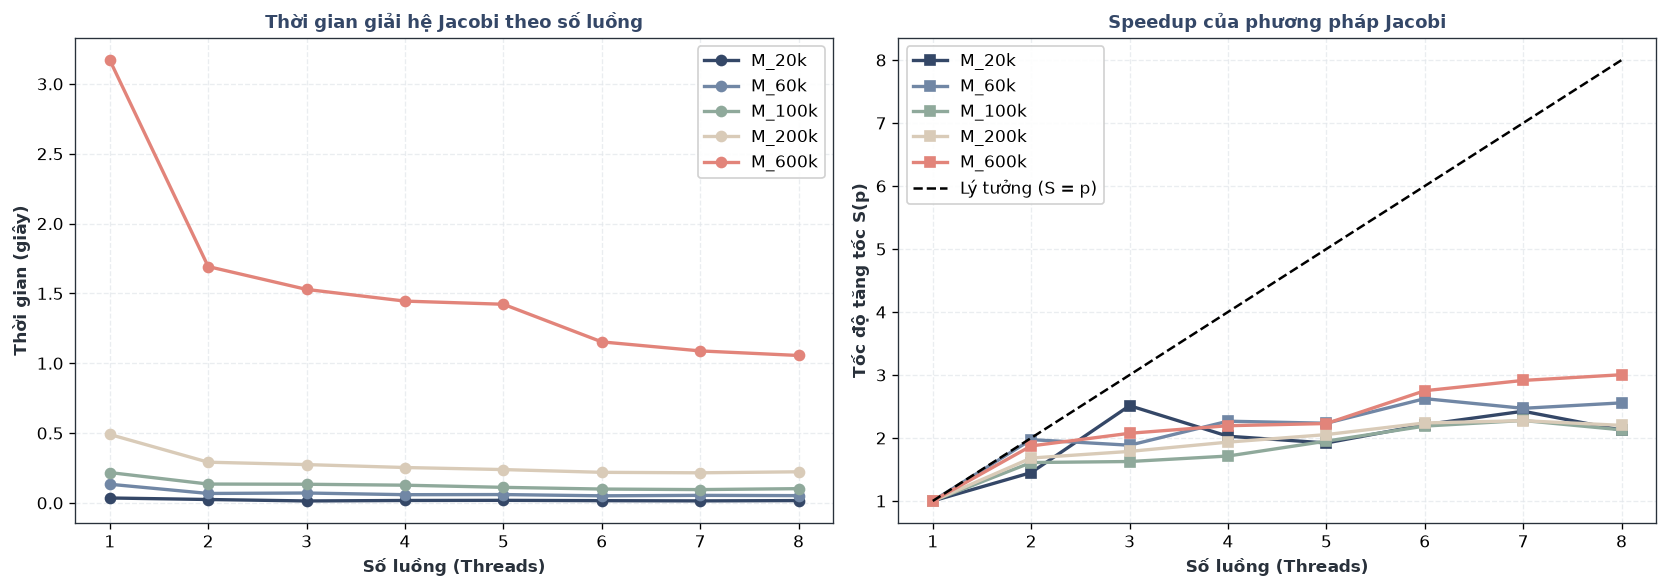

In [29]:
pivot_jacobi_time = df_jacobi.pivot(index="Matrix", columns="Threads", values="Time_Median_sec")
pivot_jacobi_time.columns = [f"{c} Luồng (s)" for c in pivot_jacobi_time.columns]

pivot_jacobi_speedup = df_jacobi.pivot(index="Matrix", columns="Threads", values="Speedup")
pivot_jacobi_speedup.columns = [f"{c} Luồng (Speedup)" for c in pivot_jacobi_speedup.columns]

print("=== THỜI GIAN THỰC THI PHƯƠNG PHÁP JACOBI (Giây) ===")
display(pivot_jacobi_time.round(4))

print("=== TỐC ĐỘ TĂNG TỐC SPEEDUP CỦA JACOBI ===")
display(pivot_jacobi_speedup.round(2))

# Biểu đồ 5: Thời gian và Speedup của Jacobi theo số luồng
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

for idx, n in enumerate(matrix_sizes):
    sub = df_jacobi[df_jacobi["N"] == n]
    ax1.plot(sub["Threads"], sub["Time_Median_sec"], marker='o', linewidth=2, 
             label=f"M_{n//1000}k", color=COLORS[idx])
    ax2.plot(sub["Threads"], sub["Speedup"], marker='s', linewidth=2, 
             label=f"M_{n//1000}k", color=COLORS[idx])

ax1.set_title("Thời gian giải hệ Jacobi theo số luồng", fontsize=11, fontweight='bold', color='#344767')
ax1.set_xlabel("Số luồng (Threads)", fontsize=10, fontweight='bold', color='#29313B')
ax1.set_ylabel("Thời gian (giây)", fontsize=10, fontweight='bold', color='#29313B')
ax1.set_xticks(thread_counts)
ax1.grid(True)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9)

ax2.plot(thread_counts, thread_counts, 'k--', linewidth=1.5, label="Lý tưởng (S = p)")
ax2.set_title("Speedup của phương pháp Jacobi", fontsize=11, fontweight='bold', color='#344767')
ax2.set_xlabel("Số luồng (Threads)", fontsize=10, fontweight='bold', color='#29313B')
ax2.set_ylabel("Tốc độ tăng tốc S(p)", fontsize=10, fontweight='bold', color='#29313B')
ax2.set_xticks(thread_counts)
ax2.grid(True)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


### Biểu đồ lịch sử hội tụ (Convergence Curve):
Đồ thị thể hiện mức độ suy giảm của sai số độ lệch $\|x^{(k+1)} - x^{(k)}\|_\infty$ theo số vòng lặp (trục tung biểu diễn thang logarit).


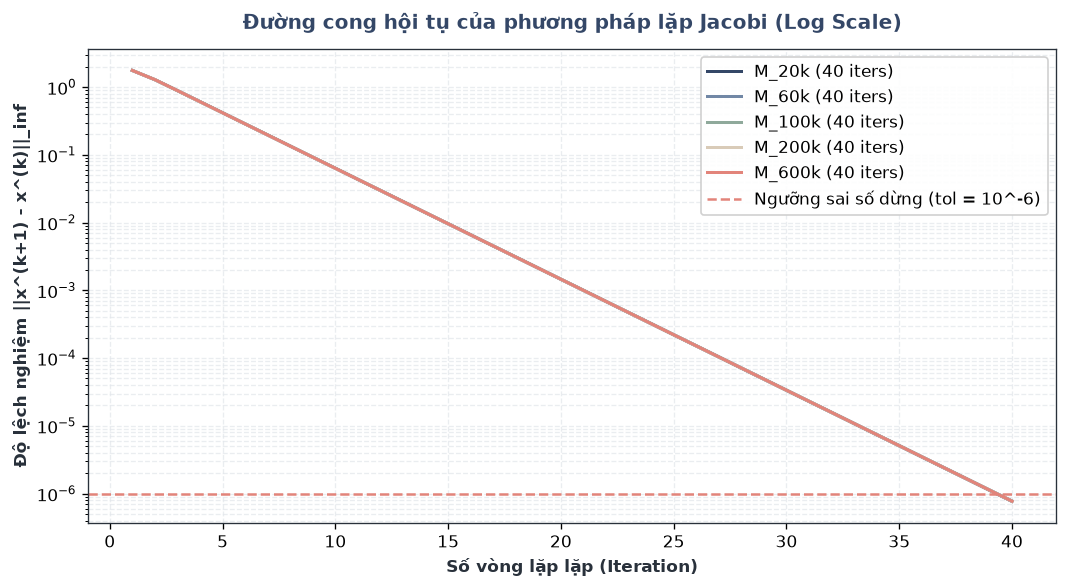

In [30]:
# Biểu đồ 6: Lịch sử hội tụ của phương pháp lặp Jacobi
plt.figure(figsize=(9, 5), dpi=120)

for idx, n in enumerate(matrix_sizes):
    hist = convergence_histories[n]
    iters = range(1, len(hist) + 1)
    plt.semilogy(iters, hist, linewidth=1.8, label=f"M_{n//1000}k ({len(hist)} iters)", color=COLORS[idx])

plt.axhline(y=1e-6, color='#E2847A', linestyle='--', linewidth=1.5, label='Ngưỡng sai số dừng (tol = 10^-6)')
plt.title("Đường cong hội tụ của phương pháp lặp Jacobi (Log Scale)", fontsize=12, fontweight='bold', color='#344767', pad=12)
plt.xlabel("Số vòng lặp lặp (Iteration)", fontsize=10, fontweight='bold', color='#29313B')
plt.ylabel("Độ lệch nghiệm ||x^(k+1) - x^(k)||_inf", fontsize=10, fontweight='bold', color='#29313B')
plt.grid(True, which="both")
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


## **5.7. Phân tích kết quả và Liên hệ bão hòa giữa SpMV và Jacobi**
Định lượng tỷ trọng thời gian của SpMV trong Jacobi:
Đo lường thời gian riêng biệt của nhân SpMV ($R \cdot x$) so với thời gian cập nhật vector nghiệm và tính sai số trong mỗi bước lặp trên hệ lớn nhất $M_{600k}$:


Thời gian trung bình một bước lặp (N = 600,000): 37.065 ms
- Nhân ma trận thưa SpMV:        34.805 ms (93.9%)
- Cập nhật vector & tính sai số: 2.260 ms (6.1%)


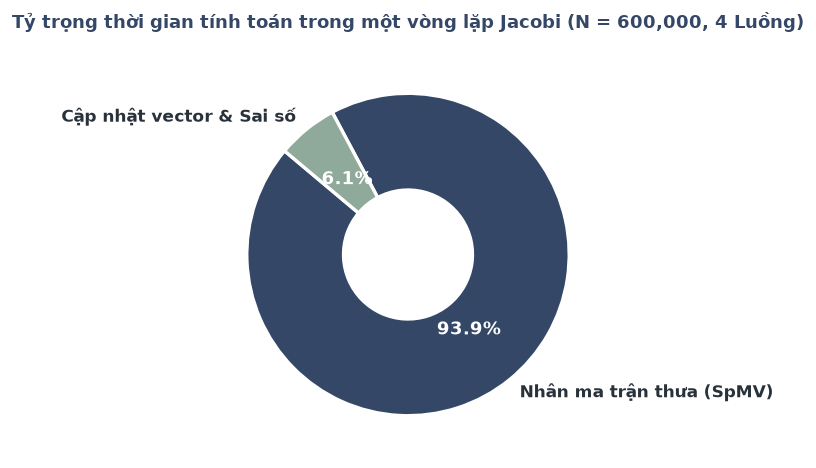

In [31]:
# Đo riêng thời gian SpMV và thời gian cập nhật vector trên ma trận M_600k (4 luồng)
sys_600k = systems[600000]
R_600k = sys_600k["R"]
n_600k = 600000
x_tmp = np.ones(n_600k, dtype=np.float64)
y_tmp = np.zeros(n_600k, dtype=np.float64)
inv_diag_600k = sys_600k["inv_diag"]
b_600k = sys_600k["b"]

set_num_threads(4)

# Đo thời gian nhân SpMV
spmv_times = []
for _ in range(20):
    t0 = time.perf_counter()
    spmv_csr_parallel(R_600k.data, R_600k.indices, R_600k.indptr, x_tmp, y_tmp, n_600k)
    t1 = time.perf_counter()
    spmv_times.append(t1 - t0)
t_spmv_step = np.median(spmv_times)

@njit(parallel=True, fastmath=True)
def update_vector_parallel(b, y, inv_diag, n):
    for i in prange(n):
        y[i] = (b[i] - y[i]) * inv_diag[i]

# Đo thời gian cập nhật vector & tính max_diff
update_times = []
for _ in range(20):
    t0 = time.perf_counter()
    update_vector_parallel(b_600k, y_tmp, inv_diag_600k, n_600k)
    compute_max_diff(x_tmp, y_tmp, n_600k)
    t1 = time.perf_counter()
    update_times.append(t1 - t0)
t_update_step = np.median(update_times)

total_step = t_spmv_step + t_update_step
spmv_pct = (t_spmv_step / total_step) * 100.0
update_pct = (t_update_step / total_step) * 100.0

print(f"Thời gian trung bình một bước lặp (N = 600,000): {total_step*1000:.3f} ms")
print(f"- Nhân ma trận thưa SpMV:        {t_spmv_step*1000:.3f} ms ({spmv_pct:.1f}%)")
print(f"- Cập nhật vector & tính sai số: {t_update_step*1000:.3f} ms ({update_pct:.1f}%)")

# Biểu đồ 7: Phân rã tỷ trọng thời gian trong mỗi vòng lặp Jacobi
fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
components = ['Nhân ma trận thưa (SpMV)', 'Cập nhật vector & Sai số']
percentages = [spmv_pct, update_pct]
colors_pie = ['#344767', '#8FA99B']

wedges, texts, autotexts = ax.pie(percentages, labels=components, autopct='%1.1f%%',
                                  startangle=140, colors=colors_pie,
                                  textprops=dict(color="#29313B", fontweight='bold'),
                                  wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2))

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(11)

plt.title("Tỷ trọng thời gian tính toán trong một vòng lặp Jacobi (N = 600,000, 4 Luồng)", 
          fontsize=11, fontweight='bold', color='#344767', pad=15)
plt.tight_layout()
plt.show()


## **5.8. Tổng kết kết quả ứng dụng**

Dưới đây là bảng tổng hợp các chỉ số thực nghiệm của phương pháp lặp Jacobi trên toàn bộ 5 ma trận:


In [32]:
jacobi_final_summary = []

for n in matrix_sizes:
    sub = df_jacobi[df_jacobi["N"] == n]
    t1 = sub[sub["Threads"] == 1]["Time_Median_sec"].values[0]
    t4 = sub[sub["Threads"] == 4]["Time_Median_sec"].values[0]
    t8 = sub[sub["Threads"] == 8]["Time_Median_sec"].values[0]
    s_max = sub["Speedup"].max()
    p_max = sub.loc[sub["Speedup"].idxmax(), "Threads"]
    err = sub["Error_to_Exact"].mean()
    iters = sub["Iterations"].values[0]
    
    jacobi_final_summary.append({
        "Hệ phương trình": f"Hệ M_{n//1000}k",
        "Số ẩn (N)": n,
        "Số vòng lặp": iters,
        "T(1) (giây)": round(t1, 4),
        "T(4) (giây)": round(t4, 4),
        "T(8) (giây)": round(t8, 4),
        "Speedup Max": f"{s_max:.2f}x ({p_max}T)",
        "Sai số max vs x*": f"{err:.2e}",
    })

df_final_jacobi_table = pd.DataFrame(jacobi_final_summary)
print("=== BẢNG TỔNG KẾT KẾT QUẢ ỨNG DỤNG JACOBI ===")
display(df_final_jacobi_table)


=== BẢNG TỔNG KẾT KẾT QUẢ ỨNG DỤNG JACOBI ===


,Hệ phương trình,Số ẩn (N),Số vòng lặp,T(1) (giây),T(4) (giây),T(8) (giây),Speedup Max,Sai số max vs x*
0,Hệ M_20k,20000,40,0.0354,0.0174,0.0167,2.51x (3T),3.12e-07
1,Hệ M_60k,60000,40,0.1337,0.0590,0.0523,2.62x (6T),3.17e-07
2,Hệ M_100k,100000,40,0.2173,0.1269,0.1021,2.28x (7T),3.16e-07
3,Hệ M_200k,200000,40,0.4902,0.2535,0.2228,2.27x (7T),3.13e-07
4,Hệ M_600k,600000,40,3.1709,1.4449,1.0556,3.00x (8T),3.15e-07
